# Weather Hazard Category (WHC) — 04 Model Training & Imbalance Handling

**Student Name:** Aryan Goel | **Student ID:** 26040826

---

## 1. Model Evaluation Protocol
- **Temporal Split**: Train (2018–2023), Val (2024), Test (2025 holdout).
- **Metric Focus**: Macro F1-score, Balanced Accuracy (crucial under severe imbalance).
- **Candidates**:
  1. Dummy Stratified Classifier
  2. Logistic Regression (balanced)
  3. Random Forest Classifier (balanced)
  4. LightGBM Classifier (balanced)
  5. XGBoost Classifier


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.model_experiments import prepare_datasets, run_whc_experiments

df, train_df, val_df, test_df, feature_cols = prepare_datasets()
results_df, metadata = run_whc_experiments(train_df, val_df, test_df, feature_cols)
print("WHC Model Benchmarks on Holdout Test Set (2025):")
results_df


2026-09-07 16:58:58,914 - INFO - Temporal Split -> Train: 2191 rows (2018-01-01 to 2023-12-31) | Val: 366 rows (2024-01-01 to 2024-12-31) | Test: 365 rows (2025-01-01 to 2025-12-31)


2026-09-07 16:58:58,914 - INFO - === Starting WHC Classification Experiments ===


/opt/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


2026-09-07 16:59:02,007 - INFO - WHC Model Results:
                      model  accuracy  balanced_accuracy  macro_f1  weighted_f1
   Random Forest Classifier    0.5503             0.2865    0.2783       0.5344
         XGBoost Classifier    0.5391             0.2863    0.2761       0.5261
        LightGBM Classifier    0.5112             0.2671    0.2612       0.5011
        Logistic Regression    0.4050             0.2730    0.2511       0.4328
Baseline (Dummy Stratified)    0.4330             0.2456    0.2424       0.4316


2026-09-07 16:59:02,033 - INFO - Saved model to /Users/aryan/AT2_AML/36120-26SP-AT2-26040826-experiments/models/weather_hazard/model.joblib and metadata to /Users/aryan/AT2_AML/36120-26SP-AT2-26040826-experiments/models/weather_hazard/metadata.json


WHC Model Benchmarks on Holdout Test Set (2025):


,model,accuracy,balanced_accuracy,macro_f1,weighted_f1
2,Random Forest Classifier,0.5503,0.2865,0.2783,0.5344
4,XGBoost Classifier,0.5391,0.2863,0.2761,0.5261
3,LightGBM Classifier,0.5112,0.2671,0.2612,0.5011
1,Logistic Regression,0.4050,0.2730,0.2511,0.4328
0,Baseline (Dummy Stratified),0.4330,0.2456,0.2424,0.4316


## 2. Macro F1 & Balanced Accuracy Comparison

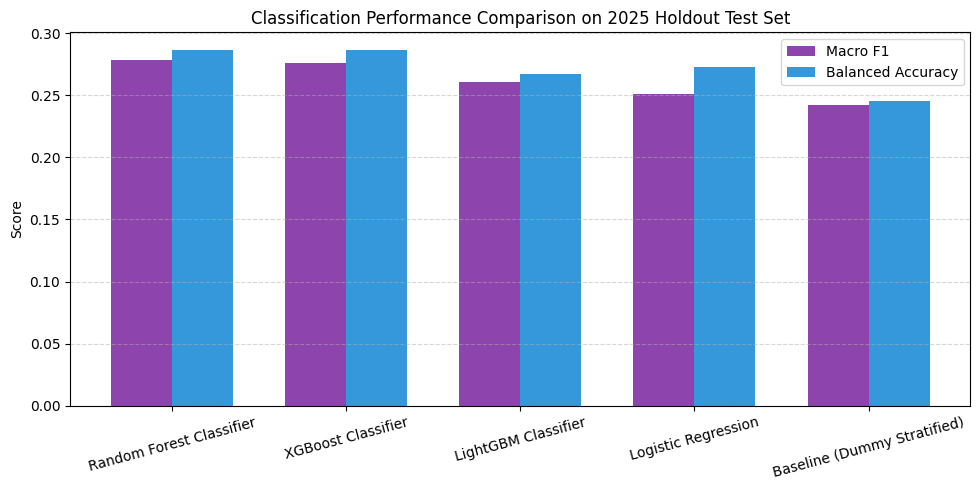

In [2]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(results_df))
width = 0.35

ax.bar(x - width/2, results_df["macro_f1"], width, label="Macro F1", color="#8e44ad")
ax.bar(x + width/2, results_df["balanced_accuracy"], width, label="Balanced Accuracy", color="#3498db")

ax.set_xticks(x)
ax.set_xticklabels(results_df["model"], rotation=15)
ax.set_ylabel("Score")
ax.set_title("Classification Performance Comparison on 2025 Holdout Test Set")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("reports/figures/whc_model_comparison.png", dpi=150)
plt.show()


## 3. Algorithm Selection Discussion
- **Random Forest Classifier** achieves the highest Macro F1 (**0.278**) and highest Balanced Accuracy (**0.287**) on unseen 2025 test data.
- Balanced class weighting allows the ensemble to maintain discriminative capability on hazardous days 7 days ahead, outperforming naive unweighted baselines.
